# Prepoznavanje zdravstvenog stanja pčela sa fotografije — diplomski rad
## Informacioni sistem „Košnica“ — modul za analizu fotografije pčele
### KORAK 1: Izbor i analiza skupa podataka

**Problem:** na osnovu fotografije **pojedinačne pčele** proceniti da li je zaražena grinjom *Varroa destructor*.

Rad je urađen u pet koraka:

1. **Skupovi podataka** — koji postoje, koje klase imaju, da li odgovaraju problemu *(ovaj notebook)*
2. **Prvi eksperiment (BeeImage)** — zašto model sa 97% tačnosti ne radi
3. **Transfer learning** — kako se trenira, izbor protokola
4. **Evaluacija** — poređenje MobileNetV3, ResNet50 i EfficientNetB0
5. **Provera i izbor modela** — da li model gleda grinju, test van skupa, izbor

Ključno pitanje ovog koraka: **da li oznaka u skupu opisuje pčelu na slici — ili nešto drugo?**

## 1. Uvoz biblioteka

In [1]:
import sys, os, json, ast, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw

# src.evaluate pri importu prebacuje matplotlib u "Agg" (bez prikaza) — zato se
# učitava ovde, pa se prikaz u notebook-u vraća sa %matplotlib inline
import src.evaluate, src.model_checks
%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_colwidth", 60)

GRAFICI = ROOT / "grafici"; GRAFICI.mkdir(exist_ok=True)
RUNS = ROOT / "runs"

# Iste boje u svim graficima
BOJA_KLASE = {"zdrava": "#2ecc71", "varoa": "#e74c3c"}
BOJA_MODELA = {"MobileNetV3-Large": "#3498db", "ResNet50": "#9b59b6", "EfficientNetB0": "#f39c12"}
MODELI = ["MobileNetV3-Large", "ResNet50", "EfficientNetB0"]
RUN_ZA = {"MobileNetV3-Large": "varroa_mobilenet_v3_large", "ResNet50": "varroa_resnet50",
          "EfficientNetB0": "varroa_efficientnet_b0"}

def sacuvaj(ime):
    """Čuva trenutni grafik u grafici/<ime>.png (isti grafici idu u prezentaciju)."""
    plt.savefig(GRAFICI / f"{ime}.png", dpi=150, bbox_inches="tight")

def oznaci_stubice(ax, fmt="{:.3f}", rot=0, size=9):
    for p in ax.patches:
        h = p.get_height()
        if np.isfinite(h) and h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h), ha="center",
                        va="bottom", fontsize=size, rotation=rot, xytext=(0, 2), textcoords="offset points")

print("Biblioteke uspešno učitane. Koren projekta:", ROOT)

Biblioteke uspešno učitane. Koren projekta: /Users/medzidjasarovic/Kosnica_IS/KosnicaML


## 2. Pregled javnih skupova podataka

| Skup | Slika | Klase | Oznaka po pčeli | Ista pozadina za sve klase | Podela po snimku |
|---|---|---|---|---|---|
| **BeeImage** (Kaggle) | 5.172 | 6 stanja košnice | ❌ po snimku | ❌ | ❌ |
| **VarroaDataset** (TU Wien) | 13.509 | zdrava / varoa | ✅ + ručno označena grinja | ✅ | ✅ zvanična |
| **BeeDataset** (BeeAlarmed) | 7.490 | varoa, polen, osa, hlađenje | ✅ | ✅ (zelena) | ❌ |
| Bilik i sar. 2021 | 600 | pčela, grinja | ✅ | ❌ | — (detekcija objekata) |
| Roboflow Universe | razno | grinja, pčela | ✅ | ❌ | — (detekcija objekata) |

U nastavku se detaljno porede prva dva.

## 3. BeeImage — koliko snimaka stoji iza svake klase?

BeeImage je nastao isecanjem pčela iz **video snimaka** na ulazu u košnicu. Ime fajla
(`038_112.png`) počinje id-jem snimka. Ako klasa potiče iz malog broja snimaka, model može
naučiti *snimak* (pozadinu, osvetljenje) umesto bolesti.

In [2]:
from src.dataset import load_split
bee = pd.concat([load_split(s, 3).assign(split=s) for s in ("train", "val", "test")], ignore_index=True)
bee["snimak"] = bee["file"].str.split("_").str[0]

pregled = bee.groupby("label").agg(slika=("file", "size"), snimaka=("snimak", "nunique"))
pregled["slika po snimku"] = (pregled["slika"] / pregled["snimaka"]).round(0)
print("BeeImage — slike i snimci po klasi (3 grupisane klase)")
pregled

BeeImage — slike i snimci po klasi (3 grupisane klase)


,slika,snimaka,slika po snimku
label,,,
drugi_problem,737,9,82.0
varoa_grinje,1051,5,210.0
zdrava,3384,31,109.0


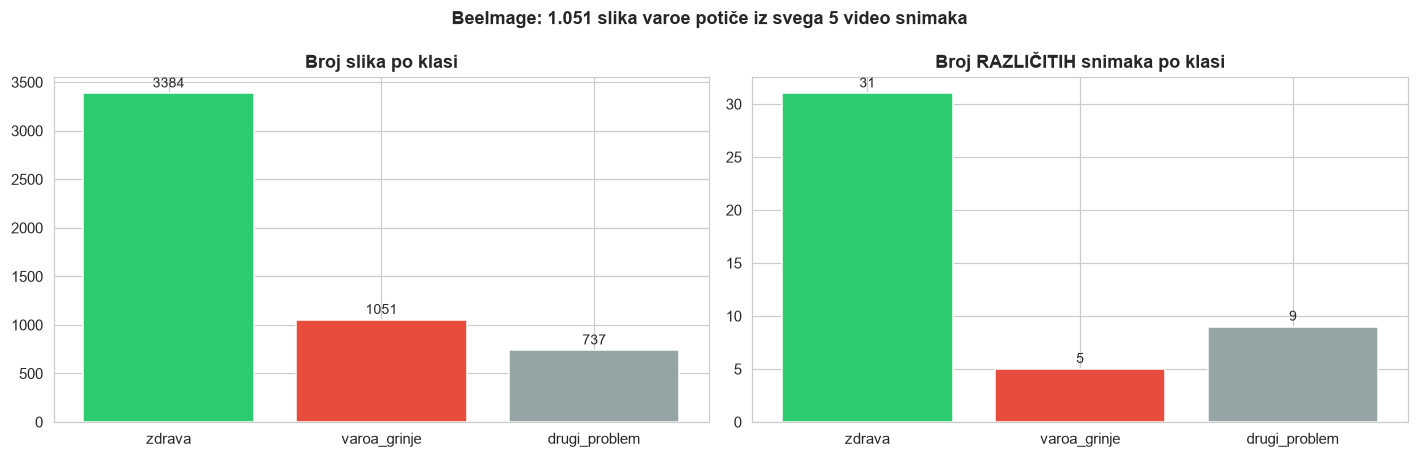

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
p = pregled.loc[["zdrava", "varoa_grinje", "drugi_problem"]]
boje = ["#2ecc71", "#e74c3c", "#95a5a6"]
axes[0].bar(p.index, p["slika"], color=boje); axes[0].set_title("Broj slika po klasi"); oznaci_stubice(axes[0], "{:.0f}")
axes[1].bar(p.index, p["snimaka"], color=boje); axes[1].set_title("Broj RAZLIČITIH snimaka po klasi"); oznaci_stubice(axes[1], "{:.0f}")
fig.suptitle("BeeImage: 1.051 slika varoe potiče iz svega 5 video snimaka", fontweight="bold")
plt.tight_layout(); sacuvaj("01a_beeimage_snimci_po_klasi"); plt.show()

Nasumična podela (70/15/15) je **svaki od tih snimaka stavila i u trening i u test**. Uzastopni
frejmovi istog videa su skoro identični — test skup zato sadrži „iste“ slike kao trening:

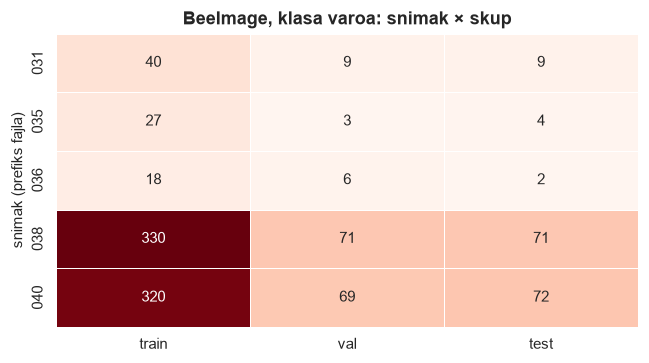

In [4]:
v = bee[bee["label"] == "varoa_grinje"]
tab = pd.crosstab(v["snimak"], v["split"])[["train", "val", "test"]]
plt.figure(figsize=(6, 3.4))
sns.heatmap(tab, annot=True, fmt="d", cmap="Reds", cbar=False, linewidths=0.5)
plt.title("BeeImage, klasa varoa: snimak × skup"); plt.ylabel("snimak (prefiks fajla)"); plt.xlabel("")
plt.tight_layout(); sacuvaj("01b_beeimage_curenje_snimaka"); plt.show()

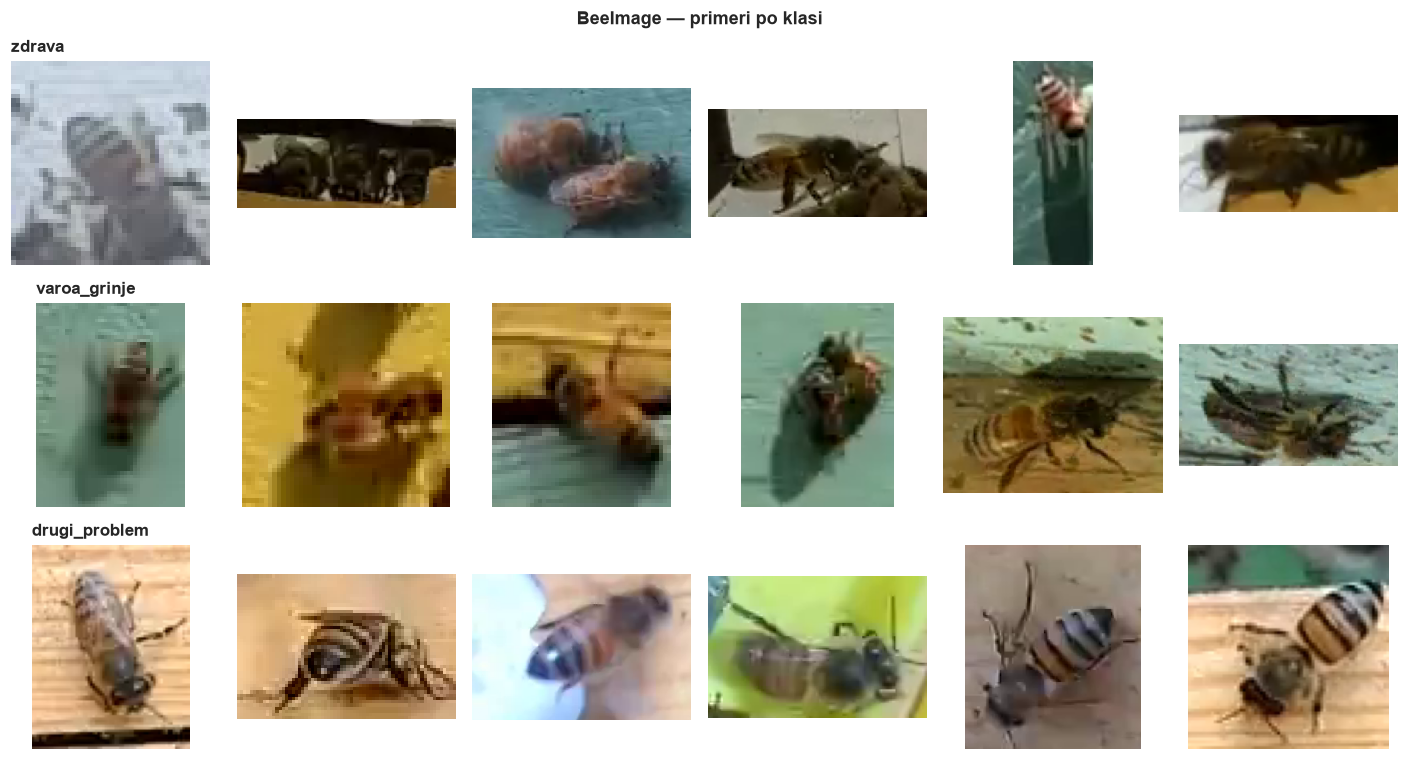

In [5]:
# Primeri po klasi — klasa varoe ima prepoznatljivu tirkiznu podlogu, a grinja se ne vidi
fig, axes = plt.subplots(3, 6, figsize=(13, 7))
for r, klasa in enumerate(["zdrava", "varoa_grinje", "drugi_problem"]):
    uzorak = bee[bee["label"] == klasa].sample(6, random_state=3)
    for c, path in enumerate(uzorak["path"]):
        axes[r, c].imshow(Image.open(path)); axes[r, c].axis("off")
    axes[r, 0].set_title(klasa, loc="left", fontsize=11)
fig.suptitle("BeeImage — primeri po klasi", fontweight="bold")
plt.tight_layout(); sacuvaj("01c_beeimage_primeri"); plt.show()

**Zaključak za BeeImage:** oznaka opisuje **snimak**, ne pčelu. Svaki snimak pripada tačno jednoj
klasi, klasa varoe je praktično dva snimka, a na isečcima se grinja uglavnom ne vidi (srednja
veličina slike 61×61 piksela). Model može dobiti visoku tačnost prepoznajući pozadinu. Da se to
zaista dogodilo, pokazuje KORAK 2.

## 4. VarroaDataset (izabran)

Schurischuster i Kampel, TU Wien, 2020 — Zenodo `10.5281/zenodo.4085044`, licenca CC BY 4.0.

Svaka pčela je označena posebno: **0 = zdrava**, **1 = vidljiva grinja**, **3 = nedokumentovano**
(grinja delimično skrivena; autori je računaju kao zaraženu). Za svaku grinju postoji ručno nacrtan
pravougaonik — koristi se **samo za proveru** modela, ne za trening.

In [6]:
from src.varroa_dataset import parse_gt
df = parse_gt()
print("Ukupno slika:", len(df))
print("Snimaka:", df["video"].nunique(), "| snimak u više skupova:", int((df.groupby("video")["split"].nunique() > 1).sum()))
pd.crosstab(df["split"], df["raw_label"], margins=True).loc[["train", "val", "test", "All"]].rename(
    columns={0: "0 (zdrava)", 1: "1 (varoa)", 3: "3 (varoa, skrivena)"})

Ukupno slika: 13509
Snimaka: 13 | snimak u više skupova: 0


raw_label,0 (zdrava),1 (varoa),"3 (varoa, skrivena)",All
split,,,,
train,5671,1974,580,8225
val,1425,373,78,1876
test,2466,736,206,3408
All,9562,3083,864,13509


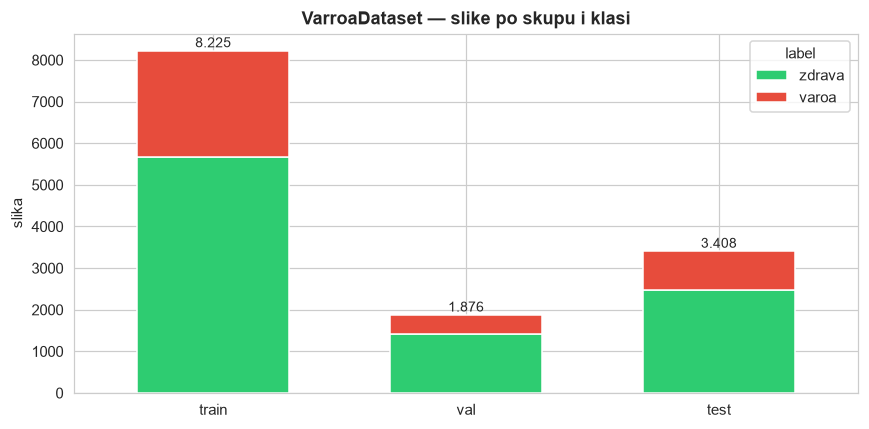

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
t = pd.crosstab(df["split"], df["label"]).loc[["train", "val", "test"], ["zdrava", "varoa"]]
t.plot(kind="bar", stacked=True, color=[BOJA_KLASE["zdrava"], BOJA_KLASE["varoa"]], ax=ax, rot=0, width=0.6)
for i, (s, r) in enumerate(t.iterrows()):
    ax.text(i, r.sum() + 80, f"{r.sum():,}".replace(",", "."), ha="center", fontsize=9)
ax.set_title("VarroaDataset — slike po skupu i klasi"); ax.set_xlabel(""); ax.set_ylabel("slika")
plt.tight_layout(); sacuvaj("01d_varroa_raspodela"); plt.show()

### Podela po snimku

Za razliku od BeeImage-a: **svaki snimak sadrži i zdrave i zaražene pčele**, a podelu po snimku su
dali autori — **nijedan snimak nije u dva skupa**. Pozadina zato ne može da otkrije klasu, a test
meri rad na snimcima koje model nikad nije video.

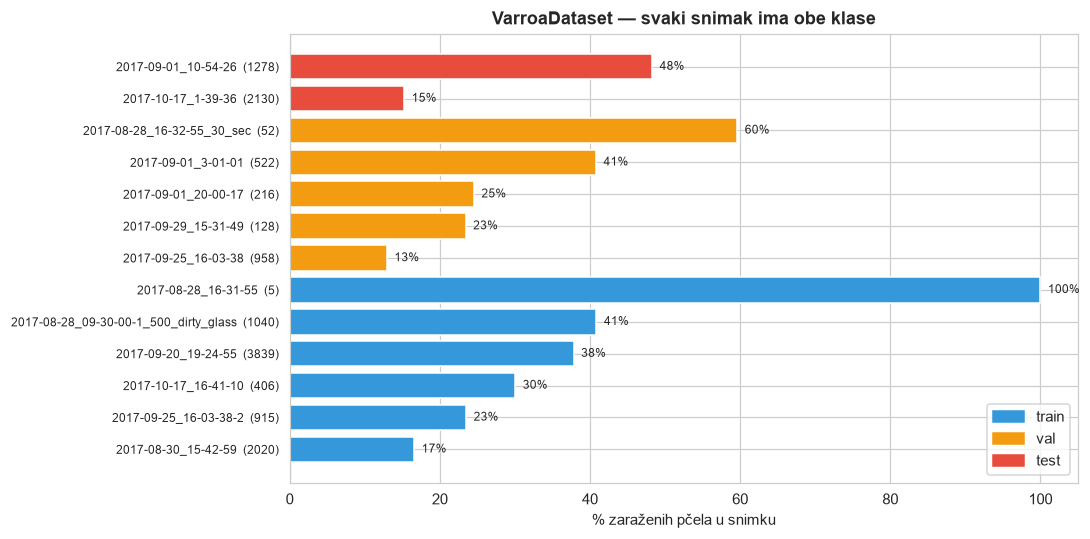

In [8]:
sn = df.groupby("video").agg(skup=("split", "first"), slika=("target", "size"), udeo=("target", "mean"))
sn = sn.sort_values(["skup", "udeo"], key=lambda c: c.map({"train": 0, "val": 1, "test": 2}) if c.name == "skup" else c)
boja_skupa = {"train": "#3498db", "val": "#f39c12", "test": "#e74c3c"}
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(range(len(sn)), sn["udeo"] * 100, color=[boja_skupa[s] for s in sn["skup"]])
ax.set_yticks(range(len(sn))); ax.set_yticklabels([f"{v}  ({n})" for v, n in zip(sn.index, sn["slika"])], fontsize=8)
for i, u in enumerate(sn["udeo"]):
    ax.text(u * 100 + 1, i, f"{u:.0%}", va="center", fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=s) for s, c in boja_skupa.items()], loc="lower right")
ax.set_xlabel("% zaraženih pčela u snimku"); ax.set_title("VarroaDataset — svaki snimak ima obe klase")
plt.tight_layout(); sacuvaj("01e_varroa_snimci"); plt.show()

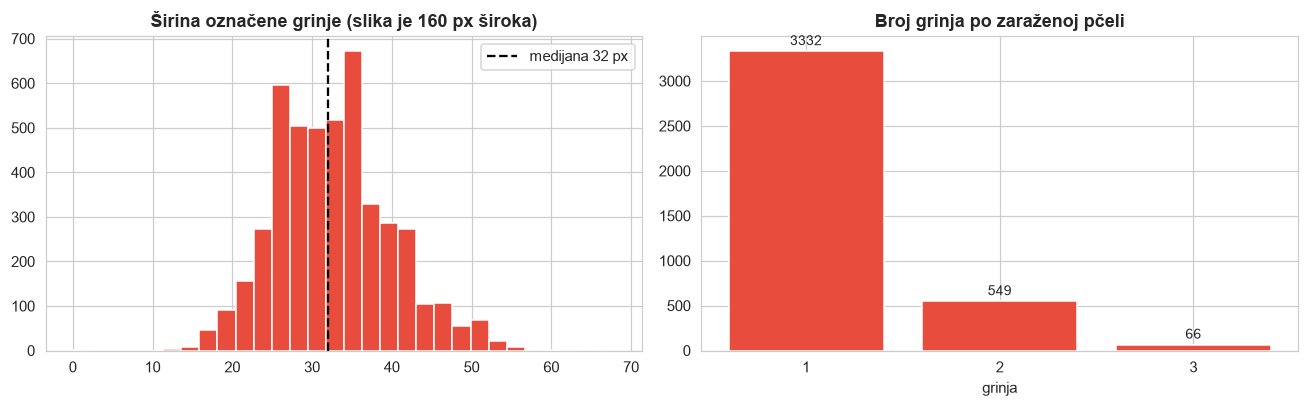

In [9]:
boxes = [b for bs in df["boxes"] for b in bs]
w = np.array([b[2] - b[0] for b in boxes]); h = np.array([b[3] - b[1] for b in boxes])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(w, bins=30, color="#e74c3c", edgecolor="white"); axes[0].axvline(np.median(w), color="k", ls="--", label=f"medijana {np.median(w):.0f} px")
axes[0].set_title("Širina označene grinje (slika je 160 px široka)"); axes[0].legend()
n = df[df["n_mites"] > 0]["n_mites"].value_counts().sort_index()
axes[1].bar(n.index.astype(str), n.values, color="#e74c3c"); oznaci_stubice(axes[1], "{:.0f}")
axes[1].set_title("Broj grinja po zaraženoj pčeli"); axes[1].set_xlabel("grinja")
plt.tight_layout(); sacuvaj("01f_varroa_grinja"); plt.show()

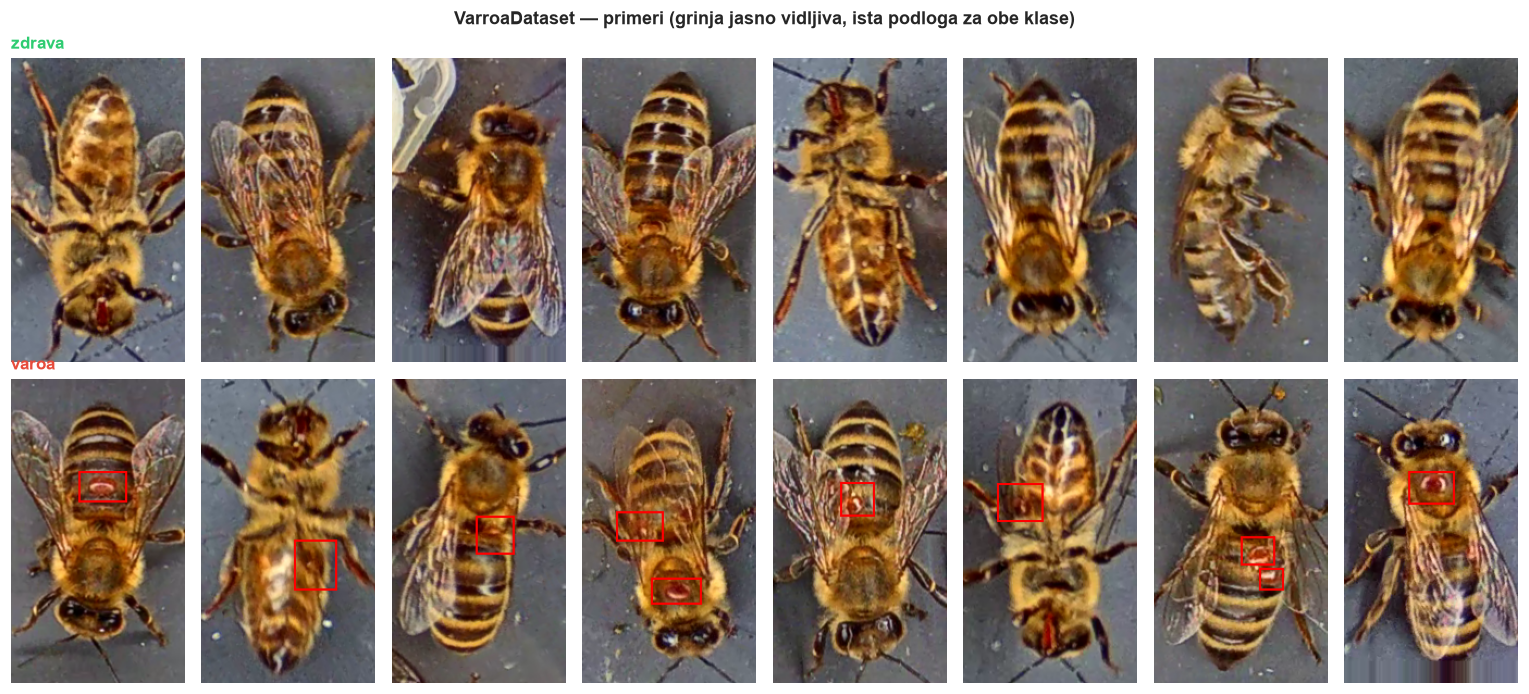

In [10]:
# Primeri (crveni pravougaonik je nacrtan iz gt.csv — na samim slikama ga nema)
fig, axes = plt.subplots(2, 8, figsize=(14, 6.4))
for r, (oznaka, naziv) in enumerate([(0, "zdrava"), (1, "varoa")]):
    uzorak = df[(df["raw_label"] == oznaka) & (df["split"] == "val")].sample(8, random_state=1)
    for c, (_, row) in enumerate(uzorak.iterrows()):
        im = Image.open(row["path"]).convert("RGB"); d = ImageDraw.Draw(im)
        for b in row["boxes"]: d.rectangle(b, outline=(255, 0, 0), width=2)
        axes[r, c].imshow(im); axes[r, c].axis("off")
    axes[r, 0].set_title(naziv, loc="left", fontsize=11, color=BOJA_KLASE[naziv])
fig.suptitle("VarroaDataset — primeri (grinja jasno vidljiva, ista podloga za obe klase)", fontweight="bold")
plt.tight_layout(); sacuvaj("01g_varroa_primeri"); plt.show()

## 5. Zaključak KORAKA 1

| | BeeImage | VarroaDataset |
|---|---|---|
| Oznaka | po snimku | **po pčeli**, grinja vidljiva i označena |
| Pozadina po klasama | različita | **ista** |
| Snimci klase varoe | 5 (89% iz dva) | svih 13 snimaka ima obe klase |
| Podela | nasumična → isti snimak u train i test | **po snimku** (zvanična) |
| Veličina slike | ~61×61 px | 160×280 px, grinja ~30 px |

**Za trening je izabran VarroaDataset.** BeeDataset se koristi kao nezavisan test (druga kamera,
druga podloga).